# 05 · Inferensi dan Generative AI

Notebook ini menunjukkan **bagaimana model dipakai** (inference) dan **bagaimana Gemini ditambahkan sebagai fitur kedua dengan pengamannya**.

## 1. Inferensi: memuat model beku

Model final (ensemble CNN + LogReg) disimpan oleh `src/train_final.py` di `models/final/`. Kelas `OrderClassifier` (`src/predictor.py`) membungkusnya: menerima teks mentah, menjalankan preprocessing, lalu mengembalikan label, confidence, penanda `needs_review`, dan probabilitas.
Kelas yang sama dipakai oleh FastAPI (`POST /classify`).

In [1]:
import os, sys, warnings
warnings.filterwarnings("ignore")
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")
os.environ.setdefault("TF_ENABLE_ONEDNN_OPTS", "0")

# Notebook ini berada di folder notebooks/; pindah ke root proyek agar path data/ dan src/ konsisten
ROOT = os.path.abspath(os.path.join(os.getcwd(), "..")) if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
sys.path.insert(0, os.path.join(ROOT, "src"))
os.chdir(ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_colwidth", 110)
pd.set_option("display.width", 170)
SEED = 42
print("Root proyek:", ROOT)

Root proyek: c:\Users\asus\firaza-custom-order


In [2]:
from predictor import OrderClassifier
clf = OrderClassifier("models/final")

pesan = [
    "Mau sajadah navy 20 pcs untuk nikahan, custom nama Budi & Sarah",
    "handuk bordir nama Dinda 2 pcs warna putih",
    "kak sajadah polos navy ready ga? mau 1 aja",
    "mau hampers lebaran isi handuk sama sajadah 25 box",
    "pesanan saya kok belum sampai, resi sudah 5 hari",
    "halo kak",
]
hasil = clf.predict_many(pesan)
pd.DataFrame([{"pesan": p, "label": r["label"], "confidence": r["confidence"], "perlu_ditinjau": r["needs_review"]}
              for p, r in zip(pesan, hasil)])

,pesan,label,confidence,perlu_ditinjau
0,"Mau sajadah navy 20 pcs untuk nikahan, custom nama Budi & Sarah",Custom Sajadah,0.9457,False
1,handuk bordir nama Dinda 2 pcs warna putih,Custom Handuk,0.9666,False
2,kak sajadah polos navy ready ga? mau 1 aja,Ready Stock,0.9262,False
3,mau hampers lebaran isi handuk sama sajadah 25 box,Hampers,0.9840,False
4,"pesanan saya kok belum sampai, resi sudah 5 hari",Other,0.9792,False
5,halo kak,Other,0.4485,True


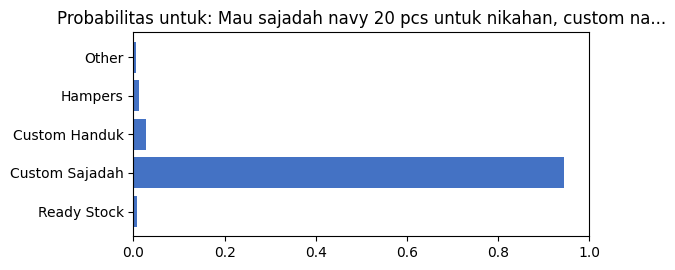

In [3]:
r = hasil[0]
fig, ax = plt.subplots(figsize=(6.2, 2.8))
ax.barh(list(r["probabilities"]), list(r["probabilities"].values()), color="#4472c4")
ax.set_xlim(0, 1); ax.set_title("Probabilitas untuk: " + pesan[0][:48] + "..."); plt.tight_layout(); plt.show()

**`needs_review`** bernilai `True` bila confidence < 0,6 (ambang awal, belum dikalibrasi). Pesan seperti "halo kak" tidak punya informasi untuk diklasifikasikan, jadi model memang tidak yakin; web menandainya agar admin memeriksa manual.

## 2. Sistem secara keseluruhan

```
Admin → Streamlit (web) → FastAPI (REST + /classify) → SQLite (6 tabel)
                                   ├→ OrderClassifier (model sendiri)
                                   └→ GenAIService → Gemini  /  fallback berbasis aturan
```
API bisa dicek bila sedang berjalan (`uvicorn api:app --app-dir src --reload`); jika tidak berjalan, sel di bawah hanya mencetak catatan.

In [4]:
import requests
try:
    print(requests.get("http://127.0.0.1:8000/health", timeout=3).json())
except Exception:
    print("API tidak sedang berjalan (normal saat sekadar membaca notebook).")
    print("Jalankan di terminal: uvicorn api:app --app-dir src --reload")

API tidak sedang berjalan (normal saat sekadar membaca notebook).
Jalankan di terminal: uvicorn api:app --app-dir src --reload


## 3. Generative AI: Gemini sebagai fitur kedua

Sesuai aturan Main Quest, **fitur pertama adalah model buatan sendiri** (klasifikasi). Gemini baru masuk sebagai fitur tambahan untuk dua hal:
1. **Structured order summary**: ringkasan terstruktur (produk, jumlah, warna, teks custom, acara, hal yang perlu diklarifikasi) dalam JSON.
2. **Draf kartu ucapan** sesuai acara dan nada.

Gemini **tidak** boleh menentukan jenis order; jenis itu berasal dari model sendiri. Prompt lengkap ada di `docs/prompts.md`.

In [5]:
import genai_service as g
print("=== SYSTEM PROMPT: structured summary ===\n" + g.SUMMARY_SYSTEM_PROMPT)
print("\n=== SYSTEM PROMPT: kartu ucapan ===\n" + g.GREETING_SYSTEM_PROMPT)

=== SYSTEM PROMPT: structured summary ===
Kamu adalah asisten admin toko Firaza (hampers, handuk, sajadah, dan kado personalisasi).
Tugasmu mengubah pesan customer menjadi ringkasan order terstruktur dalam Bahasa Indonesia.

Aturan ketat:
- Gunakan HANYA informasi yang ada di pesan customer atau data item yang diberikan. Jangan mengarang.
- Nama/teks custom harus disalin persis seperti ditulis customer (jangan diperbaiki atau diterjemahkan).
- Jumlah hanya diisi jika disebut jelas; jika tidak, isi null.
- Jika informasi penting belum jelas (jumlah, nama/teks custom, warna, font, tenggat), tulis di perlu_klarifikasi.
- Ringkasan maksimal 2 kalimat, netral, tanpa emoji.
- Jangan menentukan jenis order; itu sudah ditentukan sistem.

=== SYSTEM PROMPT: kartu ucapan ===
Kamu menulis draft kartu ucapan singkat dalam Bahasa Indonesia untuk hampers/kado dari toko Firaza.

Aturan:
- Maksimal 60 kata, 2-4 kalimat, tanpa emoji dan tanpa hashtag.
- Sesuaikan dengan acara dan nada yang diminta.
- J

### Pengaman supaya Gemini tidak mengarang

Model bahasa bisa "berhalusinasi" (menulis nama atau jumlah yang tidak ada). Pengamannya berlapis:

1. Keluaran dibatasi **skema JSON** dan divalidasi Pydantic.
2. **Grounding check**: nama dan jumlah dari Gemini harus muncul di pesan asli customer; jika tidak, dikosongkan dan diberi peringatan. Bila ada item order di database, nilai item itulah yang dipakai.
3. **Fallback** berbasis aturan bila Gemini gagal (key kosong, kuota habis, jaringan putus, JSON tidak valid), sehingga sistem tetap berfungsi.

Berikut demonstrasi grounding check dengan keluaran Gemini **tiruan yang sengaja berhalusinasi**:

In [6]:
import json
from genai_service import ground_summary, fallback_summary

brief = "Mau sajadah navy 20 pcs untuk nikahan, custom nama Budi & Sarah"
halusinasi = {"ringkasan": "Pesanan sajadah.", "acara": "nikahan", "tenggat": None, "perlu_klarifikasi": [],
              "items": [{"produk": "sajadah", "jumlah": 99, "warna": "navy", "teks_custom": "Andi", "font": None, "layout": None}],
              "sumber": "gemini", "peringatan": []}
print(json.dumps(ground_summary(halusinasi, brief, []), indent=2, ensure_ascii=False))

{
  "ringkasan": "Pesanan sajadah.",
  "acara": "nikahan",
  "tenggat": null,
  "perlu_klarifikasi": [],
  "items": [
    {
      "produk": "sajadah",
      "jumlah": null,
      "warna": "navy",
      "teks_custom": null,
      "font": null,
      "layout": null
    }
  ],
  "sumber": "gemini",
  "peringatan": [
    "Teks custom 'Andi' tidak ditemukan di pesan customer; dikosongkan",
    "Jumlah 99 tidak ditemukan di pesan customer; dikosongkan"
  ]
}


Hasilnya: nama "Andi" dan jumlah 99 **dikosongkan** karena tidak ada di pesan, dan muncul dua peringatan. Berikut ringkasan **fallback** (tanpa Gemini) untuk pesan yang sama:

In [7]:
print(json.dumps(fallback_summary(brief, [], "Custom Sajadah"), indent=2, ensure_ascii=False))

{
  "ringkasan": "Custom Sajadah: 20 pcs sajadah navy untuk nikahan, teks custom \"Budi & Sarah\".",
  "items": [
    {
      "produk": "sajadah",
      "jumlah": 20,
      "warna": "navy",
      "teks_custom": "Budi & Sarah",
      "font": null,
      "layout": null
    }
  ],
  "acara": "nikahan",
  "tenggat": null,
  "perlu_klarifikasi": [
    "Font belum dipilih"
  ],
  "sumber": "fallback",
  "peringatan": []
}


### Pemanggilan layanan sungguhan

Sel berikut memakai Gemini jika `GEMINI_API_KEY` ada di `.env`; jika tidak, otomatis memakai fallback. **Perhatikan kolom `sumber`** pada keluaran untuk mengetahui mana yang terjadi.
(Notebook yang tersimpan di repo mungkin dijalankan tanpa key; jalankan ulang di mesinmu untuk melihat hasil Gemini.)

In [8]:
svc = GenAIService = g.GenAIService()
print("Gemini aktif:", svc.available, "| model:", svc.model)
out = svc.summarize(brief, [], "Custom Sajadah")
print("sumber ringkasan:", out["sumber"])
print(json.dumps(out, indent=2, ensure_ascii=False))
kartu = svc.greeting(brief, "nikahan", "Budi & Sarah", "hangat")
print("\nsumber kartu ucapan:", kartu["sumber"])
print(kartu["kartu_ucapan"])

Gemini aktif: True | model: gemini-3.1-flash-lite


sumber ringkasan: gemini
{
  "ringkasan": "Customer memesan 20 buah sajadah warna navy dengan custom nama Budi & Sarah untuk acara pernikahan.",
  "items": [
    {
      "produk": "sajadah",
      "jumlah": 20,
      "warna": "navy",
      "teks_custom": "Budi & Sarah",
      "font": null,
      "layout": null
    }
  ],
  "acara": "nikahan",
  "tenggat": null,
  "perlu_klarifikasi": [
    "font",
    "layout"
  ],
  "sumber": "gemini",
  "peringatan": []
}

sumber kartu ucapan: fallback
Selamat menempuh hidup baru untuk Budi & Sarah. Semoga cinta kalian dipenuhi keberkahan, kebahagiaan, dan kebersamaan yang abadi.


## 4. Ringkasan alur satu order

1. Admin menempel pesan customer → **model sendiri** mengusulkan jenis order (`/classify`).
2. Admin mengonfirmasi jenis dan mencatat item (nama, jumlah, font, layout) → disimpan di database, status **New**.
3. **Gemini** menyusun ringkasan terstruktur dan draf kartu ucapan (dengan grounding check dan fallback).
4. Admin menggeser status **New → Design/Preparation → Production → Completed**; tiap perubahan tercatat di riwayat.

Dokumentasi lain: `docs/architecture.md`, `docs/model.md`, `docs/api.md`, `docs/prompts.md`, `docs/db_schema.md`, `docs/user_guide.md`.